# Lista de Exercícios 04
## Ajuste por Mínimos Quadrados

**Programa:** PPGMC / UESC  
**Base:** Burden & Faires — Capítulo 8  

---

## Objetivos

- consolidar o conceito de **mínimos quadrados**;
- comparar com **interpolação polinomial** e **splines**;
- analisar **resíduos e erro**;
- discutir **condicionamento e estabilidade numérica**.

---

## Conexão com listas anteriores

Esta lista retoma ideias de:

- Lista 2 (interpolação)
- Lista 3 (splines)

Agora com foco em **ajuste**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def ajuste_mmq_matricial(x, y, grau):

    A = np.vander(x, N=grau+1, increasing=True)
    
    AtA = A.T @ A
    Aty = A.T @ y
    
    coeficientes = np.linalg.solve(AtA, Aty)
    
    return coeficientes, A

## Exercício 1

Dados:
x = [0,1,2,3,4]  
y = [1.1,2.0,2.9,4.1,5.0]

Tarefas:
- ajustar reta
- plotar dados e ajuste
- calcular resíduos
- interpretar

Equação da Reta: y = 0.99x + 1.04

--- Resultados ---
x: 0.0, y_real: 1.1, y_ajuste: 1.04, resíduo: 0.06
x: 1.0, y_real: 2.0, y_ajuste: 2.03, resíduo: -0.03
x: 2.0, y_real: 2.9, y_ajuste: 3.02, resíduo: -0.12
x: 3.0, y_real: 4.1, y_ajuste: 4.01, resíduo: 0.09
x: 4.0, y_real: 5.0, y_ajuste: 5.00, resíduo: 0.00

Soma dos quadrados dos resíduos (SSR): 0.0270


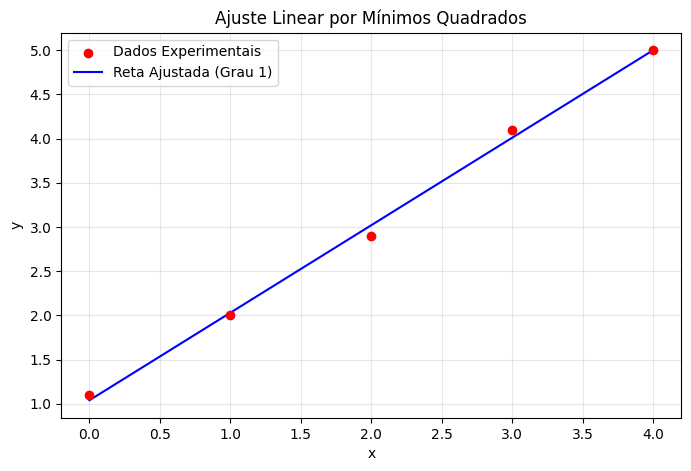

In [3]:
x = np.array([0, 1, 2, 3, 4], dtype=float)
y = np.array([1.1, 2.0, 2.9, 4.1, 5.0], dtype=float)
grau = 1

coeficientes, matriz_A = ajuste_mmq_matricial(x, y, grau)

a = coeficientes[0] 
b = coeficientes[1] 

print(f"Equação da Reta: y = {b:.2f}x + {a:.2f}")

y_fit = matriz_A @ coeficientes
residuos = y - y_fit
ssr = np.sum(residuos**2) 

print("\n--- Resultados ---")
for i in range(len(x)):
    print(f"x: {x[i]:.1f}, y_real: {y[i]:.1f}, y_ajuste: {y_fit[i]:.2f}, resíduo: {residuos[i]:.2f}")

print(f"\nSoma dos quadrados dos resíduos (SSR): {ssr:.4f}")

plt.figure(figsize=(8,5))
plt.scatter(x, y, color='red', zorder=5, label="Dados Experimentais")
plt.plot(x, y_fit, color='blue', label=f"Reta Ajustada (Grau {grau})")

plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Ajuste Linear por Mínimos Quadrados")
plt.legend()
plt.show()

**Equação da Reta:** O modelo obtido é $y = 0.99x + 1.04$. O coeficiente angular de $0.99$ indica que as variáveis crescem em proporção quase unitária.

**Análise dos Resíduos:** As diferenças entre os valores experimentais e os previstos pelo modelo são baixas, oscilando entre $-0.12$ e $0.09$. Destaca-se o ponto $x = 4.0$, onde a reta ajustada coincide perfeitamente com o dado real (resíduo zero).

**Qualidade do Ajuste (SSR):** A soma dos quadrados dos resíduos resultou em $0.0270$. Esse valor próximo a zero demonstra quantitativamente que o modelo linear representa o conjunto de dados com alta precisão e baixo erro global.

## Exercício 2

Com os mesmos dados:

- ajuste graus 1,2,3
- compare graficamente
- compare erros
- discuta aumento de grau

--- Comparação de Modelos ---

Grau 1: y = 0.9900x + 1.0400
SSR (Erro): 0.0270

Grau 2: y = 0.0214x^2 + 0.9043x + 1.0829
SSR (Erro): 0.0206

Grau 3: y = -0.0250x^3 + 0.1714x^2 + 0.6893x + 1.1129
SSR (Erro): 0.0116


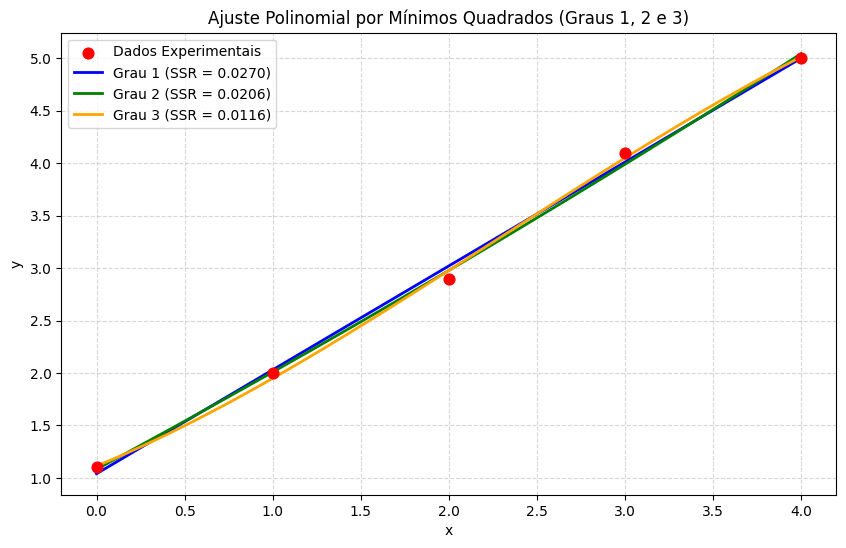

In [4]:
x = np.array([0, 1, 2, 3, 4], dtype=float)
y = np.array([1.1, 2.0, 2.9, 4.1, 5.0], dtype=float)

x_plot = np.linspace(x.min(), x.max(), 200)

graus = [1, 2, 3]
cores = ['blue', 'green', 'orange']
ssrs = [] 

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='red', s=60, zorder=5, label="Dados Experimentais")

print("--- Comparação de Modelos ---")

for i, grau in enumerate(graus):
    coeficientes, matriz_A = ajuste_mmq_matricial(x, y, grau)
    
    y_fit = matriz_A @ coeficientes
    residuos = y - y_fit
    ssr = np.sum(residuos**2)
    ssrs.append(ssr)
    
    coefs_desc = coeficientes[::-1]
    eq_str = " + ".join([f"{c:.4f}x^{grau-j}" if grau-j > 0 else f"{c:.4f}" for j, c in enumerate(coefs_desc)])
    eq_str = eq_str.replace("x^1 ", "x ").replace("+ -", "- ")
    print(f"\nGrau {grau}: y = {eq_str}")
    print(f"SSR (Erro): {ssr:.4f}")
    
    A_plot = np.vander(x_plot, N=grau+1, increasing=True)
    y_plot = A_plot @ coeficientes
    
    plt.plot(x_plot, y_plot, color=cores[i], linewidth=2, label=f"Grau {grau} (SSR = {ssr:.4f})")

plt.title("Ajuste Polinomial por Mínimos Quadrados (Graus 1, 2 e 3)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**1. Redução Contínua do Erro (SSR)**
*   Conforme o grau do polinômio aumenta de 1 para 3, o erro (SSR) diminui progressivamente de 0.0270 para 0.0116. Matematicamente, isso é o comportamento esperado: ao adicionar mais graus de liberdade (novos coeficientes), o modelo ganha flexibilidade para se curvar e se aproximar cada vez mais dos pontos experimentais exatos.

**2. O Peso dos Termos de Ordem Superior**
*   Apesar da redução no erro, os coeficientes que acompanham os termos de maior grau:
    *   No Grau 2, o coeficiente de $x^2$ é muito pequeno ($0.0214$).
    *   No Grau 3, o coeficiente de $x^3$ também é muito pequeno ($-0.0250$).
*   Isso é um forte indício de que a contribuição dessas curvaturas adicionais é marginal. A estrutura principal dos dados continua sendo dominada pelo termo linear (perto de $0.90 \sim 0.99$) e pela constante.

**3. O Risco de Sobreajuste (Overfitting)**
*   Embora o polinômio de Grau 3 apresente o menor SSR matemático, isso não significa necessariamente que ele é o melhor modelo descritivo. Se continuássemos aumentando o grau até 4, o SSR seria zero (o polinômio passaria exatamente em cima de todos os 5 pontos). No entanto, o modelo perderia sua capacidade de generalização, criando oscilações irreais entre os pontos conhecidos e falhando ao prever novos dados.

## Exercício 3 — Integrador

Função de Runge:

$f(x) = \frac{1}{(1+25x^2)}$

- gerar 10 pontos
- comparar:
  - interpolação
  - spline
  - mínimos quadrados (grau 3)
- analisar erro e estabilidade

In [5]:
def lagrange_basis(x, xs, i):
    L = 1.0
    for j in range(len(xs)):
        if j != i:
            L *= (x - xs[j]) / (xs[i] - xs[j])
    return L

def evaluate_lagrange(x_eval, xs, ys):
    y_eval = np.zeros_like(x_eval)
    for k, xv in enumerate(x_eval):
        total = 0.0
        for i in range(len(xs)):
            total += ys[i] * lagrange_basis(xv, xs, i)
        y_eval[k] = total
    return y_eval

# --- Spline Cúbico Natural ---
def cubic_spline_natural(x, a):
    n = len(x) - 1
    h = np.diff(x)
    alpha = np.zeros(n)
    for i in range(1, n):
        alpha[i] = (3.0/h[i])*(a[i+1]-a[i]) - (3.0/h[i-1])*(a[i]-a[i-1])
        
    l, mu, z = np.zeros(n+1), np.zeros(n+1), np.zeros(n+1)
    l[0] = 1.0
    for i in range(1, n):
        l[i] = 2.0*(x[i+1]-x[i-1]) - h[i-1]*mu[i-1]
        mu[i] = h[i] / l[i]
        z[i] = (alpha[i] - h[i-1]*z[i-1]) / l[i]
        
    l[n], z[n], c = 1.0, 0.0, np.zeros(n+1)
    b, d = np.zeros(n), np.zeros(n)
    for j in range(n-1, -1, -1):
        c[j] = z[j] - mu[j]*c[j+1]
        b[j] = (a[j+1]-a[j])/h[j] - h[j]*(c[j+1]+2.0*c[j])/3.0
        d[j] = (c[j+1]-c[j])/(3.0*h[j])
    return a[:-1], b, c[:-1], d

def evaluate_spline(x_eval, x, a, b, c, d):
    y_eval = np.zeros_like(x_eval)
    for k, xv in enumerate(x_eval):
        j = np.searchsorted(x, xv) - 1
        if j < 0: j = 0
        if j >= len(x) - 1: j = len(x) - 2
        dx = xv - x[j]
        y_eval[k] = a[j] + b[j]*dx + c[j]*(dx**2) + d[j]*(dx**3)
    return y_eval

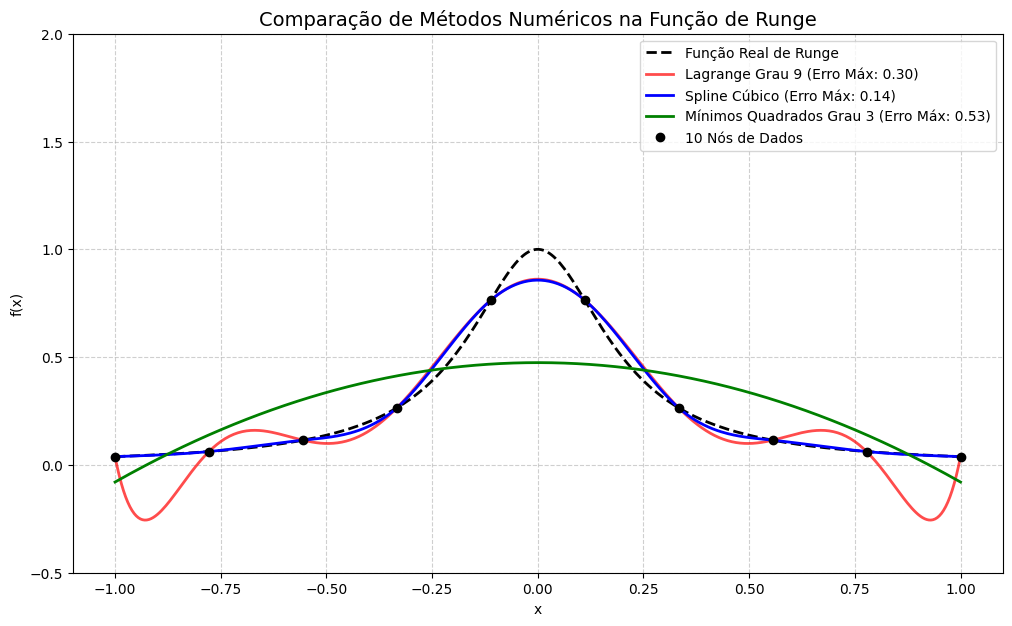

In [6]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

x_dados = np.linspace(-1, 1, 10)
y_dados = runge(x_dados)

x_plot = np.linspace(-1, 1, 400)
y_real = runge(x_plot)

y_lagrange = evaluate_lagrange(x_plot, x_dados, y_dados)

a, b, c, d = cubic_spline_natural(x_dados, y_dados)
y_spline = evaluate_spline(x_plot, x_dados, a, b, c, d)

coefs_mq, _ = ajuste_mmq_matricial(x_dados, y_dados, grau=3)
A_plot = np.vander(x_plot, N=4, increasing=True) 
y_mq = A_plot @ coefs_mq

erro_lagrange = np.max(np.abs(y_real - y_lagrange))
erro_spline = np.max(np.abs(y_real - y_spline))
erro_mq = np.max(np.abs(y_real - y_mq))

plt.figure(figsize=(12, 7))

plt.plot(x_plot, y_real, 'k--', linewidth=2, label='Função Real de Runge')
plt.plot(x_plot, y_lagrange, 'r-', alpha=0.7, linewidth=2, label=f'Lagrange Grau 9 (Erro Máx: {erro_lagrange:.2f})')
plt.plot(x_plot, y_spline, 'b-', linewidth=2, label=f'Spline Cúbico (Erro Máx: {erro_spline:.2f})')
plt.plot(x_plot, y_mq, 'g-', linewidth=2, label=f'Mínimos Quadrados Grau 3 (Erro Máx: {erro_mq:.2f})')

plt.plot(x_dados, y_dados, 'ko', markersize=6, zorder=5, label='10 Nós de Dados')

plt.title('Comparação de Métodos Numéricos na Função de Runge', fontsize=14)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.ylim(-0.5, 2) 
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**1. Interpolação Global (Lagrange Grau 9)**

Erro Máximo: 0.30

*   Análise: Embora o polinômio passe exatamente por todos os 10 pontos coletados, o erro entre os pontos é considerável. Isso evidencia o clássico Fenômeno de Runge: por ser um polinômio de grau elevado em pontos uniformemente espaçados, ele gera oscilações violentas e instáveis nas extremidades do intervalo para conseguir se ajustar ao centro da função. Fica claro que a interpolação global exata não garante um bom modelo preditivo global.

**2. Spline Cúbico Natural**

Erro Máximo: 0.14

*   Análise: Apresentou o melhor desempenho e a maior estabilidade da comparação. Embora a curva resultante não seja matematicamente idêntica à função original de Runge, ela é extremamente estável. O Spline contorna as oscilações nas bordas dividindo o problema e ajustando polinômios de baixo grau (cúbicos) entre cada par de pontos, garantindo apenas transições suaves. Ele consegue acompanhar o formato da função com a maior precisão entre os três métodos.

**3. Mínimos Quadrados (Grau 3)**

Erro Máximo: 0.53

Análise: Apresentou o maior erro da comparação. Diferente da interpolação, o método dos mínimos quadrados não obriga a curva a tocar nos pontos, o que evita as oscilações abruptas nas bordas (garantindo estabilidade). O problema neste caso é o subajuste (underfitting): um polinômio global de grau 3 simplesmente não possui flexibilidade matemática suficiente para reproduzir a curvatura aguda (o pico central) característica da Função de Runge.

## Exercício 4 — Avançado (Condicionamento)

- construir Vandermonde
- calcular cond(A)
- ajustar polinômios para y=exp(x)
- comparar normal vs lstsq
- discutir estabilidade

In [7]:
def vander(x, N):
    x = np.asarray(x, dtype=float).ravel()
    A = np.zeros((len(x), N))
    
    A[:, 0] = 1.0 
    for j in range(1, N):
        A[:, j] = A[:, j-1] * x
    
    return A

--- Análise de Condicionamento (Grau 12) ---
cond(A):     6.67e+10
cond(A^T A): 9.73e+20

--- Erro Residual ---
Erro Equações Normais: 1.1407e-07
Erro lstsq (SVD):      8.8701e-11


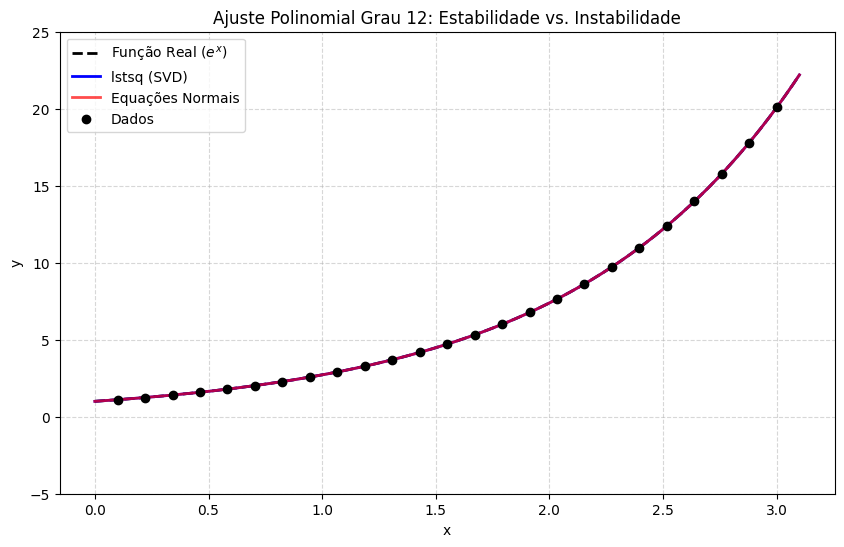

In [8]:
x = np.linspace(0.1, 3.0, 25)
y = np.exp(x)

grau = 12

A = vander(x, grau + 1)

cond_A = np.linalg.cond(A)
cond_AtA = np.linalg.cond(A.T @ A)

print(f"--- Análise de Condicionamento (Grau {grau}) ---")
print(f"cond(A):     {cond_A:.2e}")
print(f"cond(A^T A): {cond_AtA:.2e}")

#Equações Normais
AtA = A.T @ A
Aty = A.T @ y

c_normal = np.linalg.solve(AtA, Aty)
y_normal = A @ c_normal
erro_normal = np.linalg.norm(y - y_normal)

# lstsq
c_lstsq, _, _, _ = np.linalg.lstsq(A, y, rcond=None)
y_lstsq = A @ c_lstsq
erro_lstsq = np.linalg.norm(y - y_lstsq)

print(f"\n--- Erro Residual ---")
print(f"Erro Equações Normais: {erro_normal:.4e}")
print(f"Erro lstsq (SVD):      {erro_lstsq:.4e}")

x_plot = np.linspace(0, 3.1, 400)
A_plot = np.vander(x_plot, grau + 1, increasing=True)

y_plot_normal = A_plot @ c_normal
y_plot_lstsq = A_plot @ c_lstsq
y_real = np.exp(x_plot)

plt.figure(figsize=(10, 6))
plt.plot(x_plot, y_real, 'k--', linewidth=2, label='Função Real ($e^x$)')
plt.plot(x_plot, y_plot_lstsq, 'b-', linewidth=2, label='lstsq (SVD)')
plt.plot(x_plot, y_plot_normal, 'r-', alpha=0.7, linewidth=2, label='Equações Normais')

plt.scatter(x, y, color='black', label='Dados', zorder=5)

plt.title(f"Ajuste Polinomial Grau {grau}: Estabilidade vs. Instabilidade")
plt.xlabel("x")
plt.ylabel("y")
plt.ylim(-5, 25) 
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


**1. Condicionamento**

*   O número de condição da matriz original é cond(A) = 6.67e+10. Embora seja um valor alto, ele ainda opera dentro do limite de segurança da precisão dupla de ponto flutuante do computador.

*   Ao construir o sistema pelas Equações Normais, o condicionamento explode para cond(A^T A) = 9.73e+20. Esse valor ultrapassa o limite da precisão de máquina. A matriz perde toda a sua informação útil em meio a erros de arredondamento. Isso comprova na prática a relação matemática de que o condicionamento é elevado ao quadrado.

**2. O Impacto Direto no Erro Residual**

*   lstsq via SVD: O erro residual ficou na casa de 8.87e-11. Como a Decomposição em Valores Singulares operou diretamente na matriz original A, o algoritmo conseguiu contornar a instabilidade e manter uma precisão altíssima.

*   Equações Normais: O erro subiu para 1.14e-07. Devido ao colapso numérico na matriz A^T A, os cálculos foram corrompidos. O erro residual gerado pelo método normal foi muito maior que o do método SVD, comprovando a instabilidade de construir A^T A explicitamente no código para polinômios de grau elevado.

In [9]:
A.shape

(25, 13)

In [10]:
A.T.shape

(13, 25)

In [11]:
(A.T @ A).shape

(13, 13)